# Lab 04 · Descida do gradiente na regressão linear

*Machine Learning Specialization · Curso 1, semana 1 · Andrew Ng, Stanford Online e DeepLearning.AI. Adaptação em português do laboratório e das capturas da aula.*

No Lab 03 você escolheu uma inclinação e mediu o custo. Agora o próprio algoritmo ajusta a inclinação $w$ e o intercepto $b$. Execute as células em ordem e acompanhe a primeira atualização à mão antes de rodar as 10.000 iterações.

## 1. Quanto custa a reta inicial?

A área $x$ está em milhares de pés quadrados e o preço $y$ em milhares de dólares. As duas casas custaram 300 e 500 mil dólares. A reta prevê $wx+b$. Começando com os dois parâmetros em zero, ela prevê zero para ambas as casas.

A função abaixo recupera a conta do laboratório anterior. Para cada casa, calcula o erro, eleva ao quadrado e acumula. Ao final, divide por duas vezes o número de casas.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([1.0, 2.0])
y = np.array([300.0, 500.0])

def calcular_custo(x, y, w, b):
    soma = 0
    for area, preco in zip(x, y):
        erro = w * area + b - preco
        soma += erro ** 2
    return soma / (2 * len(x))

print("Custo inicial:", calcular_custo(x, y, 0, 0))

## 2. Como o algoritmo escolhe o próximo passo?

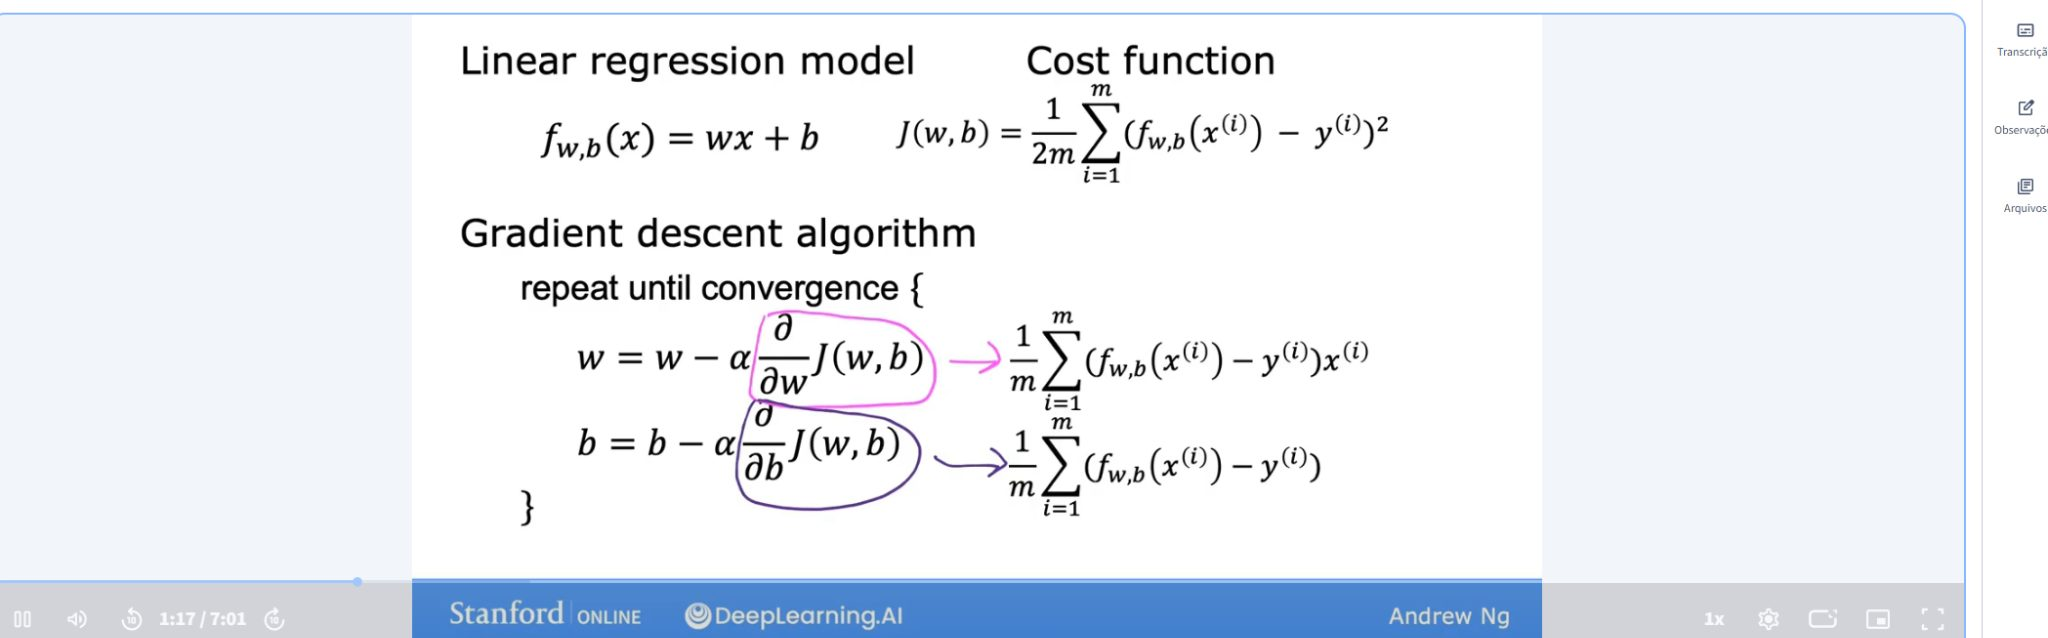

O gradiente reúne duas derivadas parciais. Cada uma mede como o custo varia quando mexemos em um parâmetro e mantemos o outro fixo. Subtraímos o gradiente para andar na direção em que o custo diminui localmente. A taxa de aprendizado $\alpha$ controla o tamanho do passo.

$$w_{novo}=w-\alpha\frac{\partial J}{\partial w},\qquad b_{novo}=b-\alpha\frac{\partial J}{\partial b}$$

As duas derivadas usam a **mesma reta atual**. Só depois de calculá-las atualizamos os dois parâmetros.

### Por que aparece um x na derivada de w?

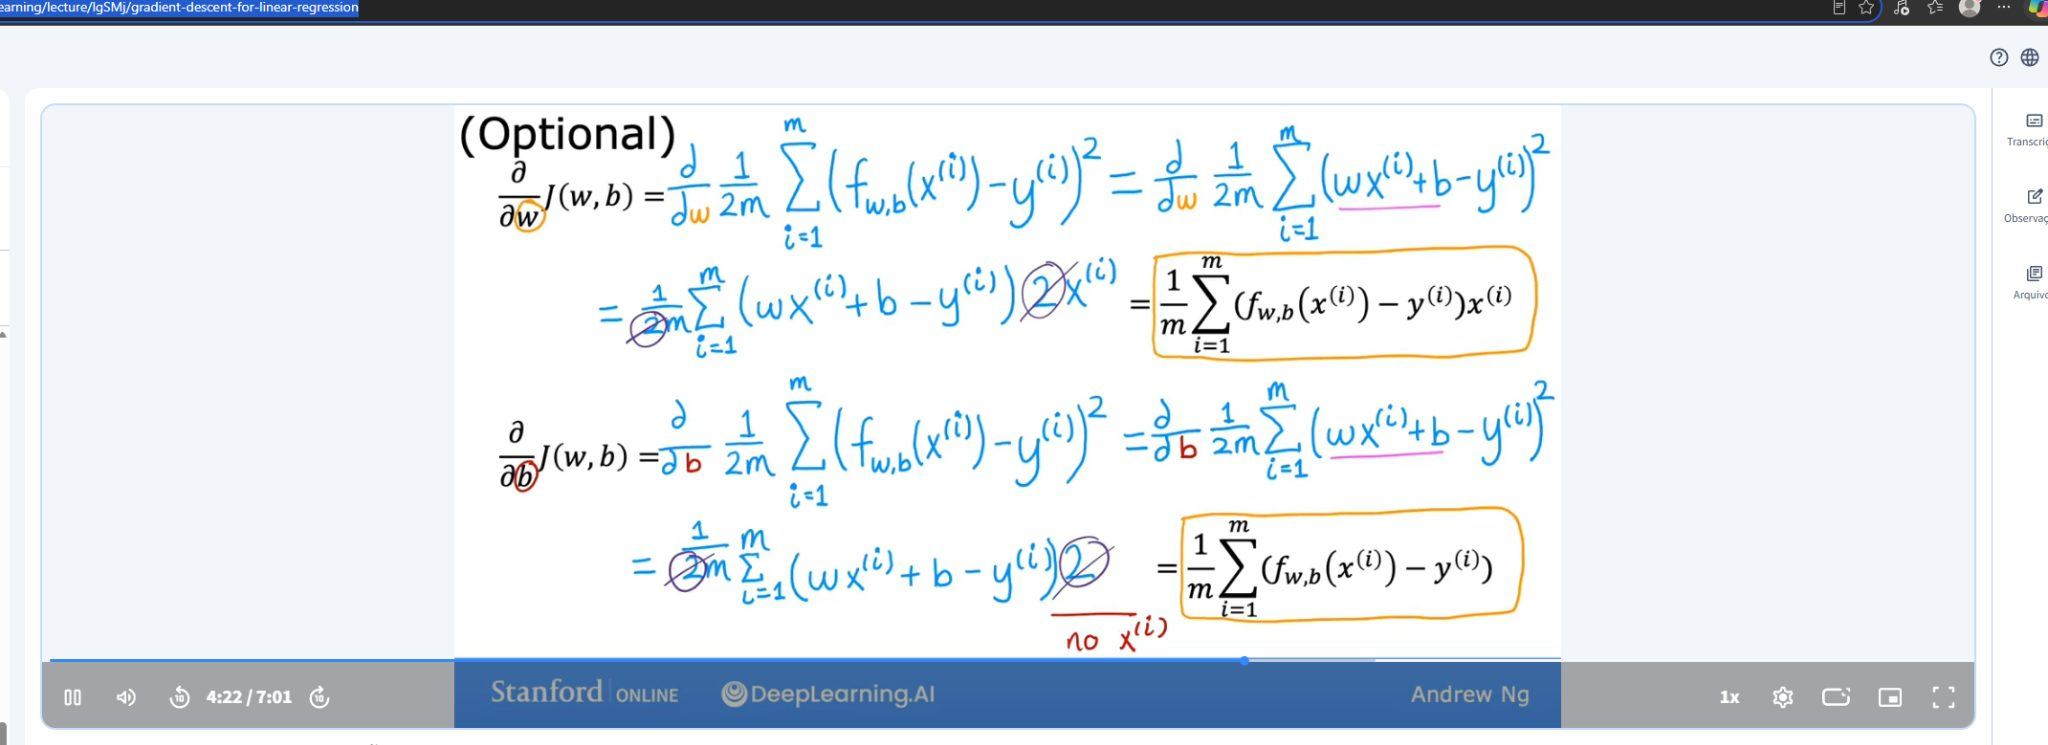

Chame o erro de cada casa de $e_i=wx_i+b-y_i$. O custo soma $e_i^2/(2m)$. Pela regra da cadeia, derivar o quadrado produz $2e_i$ multiplicado pela derivada de dentro. O 2 cancela o 2 do denominador. Sobram duas contas diferentes.

| Parâmetro | Derivada de dentro | Contribuição de uma casa antes da média |
|---|---|---|
| $w$ | $x_i$, pois $w$ multiplica a área | $e_i x_i$ |
| $b$ | $1$, pois $b$ é somado diretamente | $e_i$ |

No código, `grad_w` acumula os valores de $e_i x_i$ e `grad_b` acumula os valores de $e_i$. Dividir cada soma por $m$ completa a média.

In [ ]:
def calcular_gradiente(x, y, w, b):
    grad_w = 0.0
    grad_b = 0.0
    for area, preco in zip(x, y):
        erro = w * area + b - preco
        grad_w += erro * area
        grad_b += erro
    return grad_w / len(x), grad_b / len(x)

### Faça a primeira iteração à mão

Partindo de $(0,0)$, os erros são −300 e −500. A derivada em relação a $w$ é $(-300×1-500×2)/2=-650$. A derivada em relação a $b$ é $(-300-500)/2=-400$. Com $\alpha=0{,}01$, obtemos $w=6{,}5$ e $b=4$. Confira se a nova reta tem custo menor que os 85.000 iniciais.

In [ ]:
dw, db = calcular_gradiente(x, y, 0, 0)
w1, b1 = -0.01 * dw, -0.01 * db
print(f"w = {w1:g}, b = {b1:g}, custo = {calcular_custo(x, y, w1, b1):.2f}")

## 3. Repita o passo e guarde o caminho

A posição zero do histórico guarda a reta inicial. Cada passagem pelo laço calcula o gradiente usando todas as casas, atualiza a reta e guarda os novos parâmetros e o custo. Assim podemos inspecionar qualquer iteração depois do treino.

In [ ]:
def descida_do_gradiente(x, y, w, b, alfa, iteracoes):
    historico = [(w, b, calcular_custo(x, y, w, b))]
    for _ in range(iteracoes):
        dw, db = calcular_gradiente(x, y, w, b)
        w, b = w - alfa * dw, b - alfa * db
        historico.append((w, b, calcular_custo(x, y, w, b)))
    return np.array(historico)

trajetoria = descida_do_gradiente(x, y, w=0, b=0, alfa=0.01, iteracoes=10_000)
w, b, custo = trajetoria[-1]
print(f"Após o treino: w = {w:.3f}, b = {b:.3f}, custo = {custo:.8f}")

### Leia o histórico

À esquerda, acompanhe a queda inicial do custo. À direita, a escala vertical muda para revelar ajustes pequenos a partir da iteração 1.000. Repare nos valores dos eixos ao comparar os dois painéis.

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for eixo, inicio, fim in [(eixos[0], 0, 100), (eixos[1], 1000, 10000)]:
    eixo.plot(range(inicio, fim + 1), trajetoria[inicio:fim + 1, 2])
    eixo.set(xlabel="Iteração", ylabel="Custo", title=f"Passos {inicio} a {fim}")
plt.show()

### Veja o caminho no mapa de custo

Cada curva reúne pares $(w,b)$ com o mesmo custo. A linha laranja percorre as retas visitadas durante o treino. O segundo painel amplia a região em torno de $(200,100)$, onde a reta passa pelas duas casas.

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for eixo, (w_min, w_max, b_min, b_max), niveis in [
    (eixos[0], (-10, 245, -10, 170), [5, 50, 500, 5000, 25000, 75000]),
    (eixos[1], (180, 220, 80, 120), [1, 5, 10, 20, 100, 500]),
]:
    W, B = np.meshgrid(np.linspace(w_min, w_max, 150), np.linspace(b_min, b_max, 150))
    eixo.contour(W, B, calcular_custo(x, y, W, B), levels=niveis)
    eixo.plot(trajetoria[:, 0], trajetoria[:, 1], color="tab:orange")
    eixo.scatter(w, b, marker="x", color="black")
    eixo.set(xlabel="Inclinação w", ylabel="Intercepto b",
             xlim=(w_min, w_max), ylim=(b_min, b_max))
plt.show()

## 4. Use a reta para prever

As casas de 1.000 e 2.000 pés quadrados estavam no treino. A de 1.200 fica entre as duas. Com $w$ próximo de 200 e $b$ próximo de 100, quanto você espera que o modelo preveja para essa terceira área?

In [ ]:
for area in [1.0, 1.2, 2.0]:
    previsao = w * area + b
    print(f"{area * 1000:.0f} pés² → {previsao:.1f} mil dólares")

## 5. O que acontece quando o passo é grande demais?

Recomece do zero e mude apenas a taxa para 0,8. Compare os dez primeiros passos das duas execuções. A escala logarítmica permite enxergar as duas curvas juntas. Neste conjunto, a taxa maior faz a reta ultrapassar o mínimo repetidamente e o custo crescer.

In [ ]:
instavel = descida_do_gradiente(x, y, w=0, b=0, alfa=0.8, iteracoes=10)
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
eixos[0].plot(instavel[:, 0], marker="o")
eixos[0].set(xlabel="Iteração", ylabel="Inclinação w", title="Oscilação com α = 0,8")
eixos[1].semilogy(trajetoria[:11, 2], label="α = 0,01")
eixos[1].semilogy(instavel[:, 2], label="α = 0,8")
eixos[1].set(xlabel="Iteração", ylabel="Custo (escala logarítmica)")
eixos[1].legend()
plt.show()

**Para revisar.** Se as duas casas tivessem erro de +10, qual seria cada derivada? Calcule antes de conferir. A de $b$ seria $(10+10)/2=10$, e a de $w$ seria $(10×1+10×2)/2=15$. Com uma taxa positiva, a próxima atualização reduziria os dois parâmetros.